# 03 Model: calendar regression, then gradient boosting with lags

**Step 5:** two models, trained walk-forward: a linear regression on calendar features, then a gradient-boosted model that also uses past demand.
**Step 6:** compare with the baselines and with Eskom's published forecast, and add prediction intervals.
**Step 7:** where and when the forecast goes wrong, for the control room.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

from datetime import date, timedelta

EASTER_SUNDAY = {2022: date(2022, 4, 17), 2023: date(2023, 4, 9), 2024: date(2024, 3, 31),
                 2025: date(2025, 4, 20), 2026: date(2026, 4, 5), 2027: date(2027, 3, 28)}
SPECIAL = {date(2023, 12, 15): "Rugby World Cup holiday", date(2024, 5, 29): "National elections"}

def sa_public_holidays(years):
    """South African public holidays (Public Holidays Act): a holiday on a Sunday moves to the next free day."""
    days = {}
    for y in years:
        fixed = {(1, 1): "New Year's Day", (3, 21): "Human Rights Day", (4, 27): "Freedom Day",
                 (5, 1): "Workers' Day", (6, 16): "Youth Day", (8, 9): "National Women's Day",
                 (9, 24): "Heritage Day", (12, 16): "Day of Reconciliation", (12, 25): "Christmas Day",
                 (12, 26): "Day of Goodwill"}
        for (m, d), name in fixed.items():
            days[date(y, m, d)] = name
        days[EASTER_SUNDAY[y] - timedelta(days=2)] = "Good Friday"
        days[EASTER_SUNDAY[y] + timedelta(days=1)] = "Family Day"
    for d in sorted(list(days)):
        if d.weekday() == 6:
            nxt = d + timedelta(days=1)
            while nxt in days:
                nxt += timedelta(days=1)
            days[nxt] = days[d] + " (observed)"
    days.update({d: n for d, n in SPECIAL.items() if d.year in years})
    return days

import numpy as np
import pandas as pd

hourly = pd.read_parquet("../data/processed/hourly.parquet")
baselines = pd.read_parquet("../data/processed/baseline_forecasts.parquet")
y = hourly["demand"]
TEST_START = pd.Timestamp("2025-10-07")
origins = pd.date_range(TEST_START, periods=52, freq="7D")
hol = sa_public_holidays(range(2022, 2028))

## 1. Features

Everything a model uses must be **known when the forecast is made**, up to 7 days ahead:

- **Calendar:** hour, day of week, month, a smooth day-of-year cycle (sine and cosine), public holiday, day before and after a holiday, and a time trend.
- **Lagged demand** (gradient boosting only): demand at the same hour 1, 2, 3 and 4 weeks earlier, and the average of the last full week before the forecast week. A lag of 168 hours is always known for a forecast up to 168 hours ahead, so these never leak the future.

Weather (temperature drives winter heating) would help a lot but is not in this dataset; that is the main limitation, discussed in the README.

In [2]:
def build_features(index, demand):
    f = pd.DataFrame(index=index)
    f["hour"] = index.hour
    f["dow"] = index.dayofweek
    f["month"] = index.month
    f["doy_sin"] = np.sin(2 * np.pi * index.dayofyear / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * index.dayofyear / 365.25)
    dates = index.date
    f["holiday"] = [d in hol for d in dates]
    f["day_before_holiday"] = [(d + timedelta(days=1)) in hol for d in dates]
    f["day_after_holiday"] = [(d - timedelta(days=1)) in hol for d in dates]
    f["trend"] = (index - pd.Timestamp("2022-04-01")).days / 365.25
    for k in range(1, 5):
        f[f"lag_{k}w"] = demand.shift(168 * k).reindex(index).values
    f["last_week_mean"] = demand.shift(168).rolling(168).mean().reindex(index).values
    return f.astype(float)

full_index = pd.date_range(y.index.min(), origins[-1] + pd.Timedelta(hours=167), freq="h")
X_all = build_features(full_index, y)
CALENDAR = ["hour", "dow", "month", "doy_sin", "doy_cos", "holiday", "day_before_holiday", "day_after_holiday", "trend"]
LAGS = ["lag_1w", "lag_2w", "lag_3w", "lag_4w", "last_week_mean"]
X_all.dropna().head(3)

,hour,dow,month,doy_sin,doy_cos,holiday,day_before_holiday,day_after_holiday,trend,lag_1w,lag_2w,lag_3w,lag_4w,last_week_mean
2022-04-29 00:00:00,0.0,4.0,4.0,0.888701,-0.458487,0.0,0.0,0.0,0.07666,21949.072,20779.522,21582.411,22240.789,25335.165637
2022-04-29 01:00:00,1.0,4.0,4.0,0.888701,-0.458487,0.0,0.0,0.0,0.07666,21627.590,20308.216,21441.822,22043.880,25343.019054
2022-04-29 02:00:00,2.0,4.0,4.0,0.888701,-0.458487,0.0,0.0,0.0,0.07666,21578.205,20135.588,21557.650,21880.597,25351.606060


## 2. Model 1: linear regression on the calendar

A linear model cannot learn "8pm on a winter weekday" from separate hour, day and month columns, so the calendar is **one-hot encoded with interactions**: hour by weekday-type (weekday, Saturday, Sunday or holiday), and hour by month. This is a transparent, classic electricity-demand model.

In [3]:
from sklearn.linear_model import Ridge

def calendar_design(f):
    daytype = np.where(f.holiday == 1, "sunhol", np.where(f.dow == 6, "sunhol", np.where(f.dow == 5, "sat", "wkday")))
    d = pd.DataFrame(index=f.index)
    d["key_hd"] = f.hour.astype(int).astype(str) + "_" + daytype
    d["key_hm"] = f.hour.astype(int).astype(str) + "_" + f.month.astype(int).astype(str)
    out = pd.get_dummies(d, dtype=float)
    out["doy_sin"], out["doy_cos"], out["trend"] = f.doy_sin, f.doy_cos, f.trend
    out["day_before_holiday"], out["day_after_holiday"] = f.day_before_holiday, f.day_after_holiday
    return out

D_all = calendar_design(X_all)

## 3. Walk-forward validation

For each of the 52 test weeks: forecast its 168 hours using a model trained only on data from **before** that week, then move on a week. To keep run time reasonable the models are **retrained every 4 weeks** (13 times over the year); in between, each weekly forecast still uses the latest actual demand through its lag features. This gives 52 honest week-ahead forecasts covering every season.

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor

FEATS = CALENDAR + LAGS
train_mask_base = X_all[FEATS].notna().all(axis=1)
pred_ridge, pred_hgb = [], []
RETRAIN_EVERY = 4  # weeks
for i, origin in enumerate(origins):
    week = pd.date_range(origin, periods=168, freq="h")
    if i % RETRAIN_EVERY == 0:
        train_idx = X_all.index[(X_all.index < origin) & train_mask_base]
        ridge = Ridge(alpha=1.0).fit(D_all.loc[train_idx], y.loc[train_idx])
        hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                            categorical_features=[FEATS.index("dow")], random_state=42)
        hgb.fit(X_all.loc[train_idx, FEATS], y.loc[train_idx])
    pred_ridge.append(pd.Series(ridge.predict(D_all.loc[week]), index=week))
    pred_hgb.append(pd.Series(hgb.predict(X_all.loc[week, FEATS]), index=week))

forecasts = baselines.copy()
forecasts["calendar_regression"] = pd.concat(pred_ridge)
forecasts["gradient_boosting"] = pd.concat(pred_hgb)

def scores(frame, cols):
    out = {}
    for c in cols:
        err = frame[c] - frame.actual
        out[c] = {"MAPE (%)": (err.abs() / frame.actual).mean() * 100, "MAE (MW)": err.abs().mean(), "bias (MW)": err.mean()}
    return pd.DataFrame(out).T.round(2)

scores(forecasts, ["seasonal_naive", "four_week_average", "calendar_regression", "gradient_boosting"])

,MAPE (%),MAE (MW),bias (MW)
seasonal_naive,3.64,817.98,15.02
four_week_average,3.70,826.43,57.14
calendar_regression,5.22,1161.35,887.13
gradient_boosting,3.11,704.25,30.73


**Reading the results.**

- The **calendar regression** is the worst of all, worse even than the baselines, and its bias shows why: it over-forecasts by almost 900 MW on average. It learns the level of demand from four years of history in which demand kept falling, and a straight-line trend cannot keep up with a decline that is speeding up. It is a useful lesson: a model that knows the calendar but not the recent level loses to "same as last week".
- **Gradient boosting** combines the calendar with **recent demand** (the lags), so it picks up the current level automatically and still knows that next Tuesday is a holiday. It beats the seasonal naive forecast by about 15% (3.1% against 3.6% MAPE) and goes forward.

The chart below shows what it relies on: mostly demand at the same hour one week earlier, then two to four weeks earlier, then the hour of day and the holiday flag. The trend feature adds nothing once the lags are there.

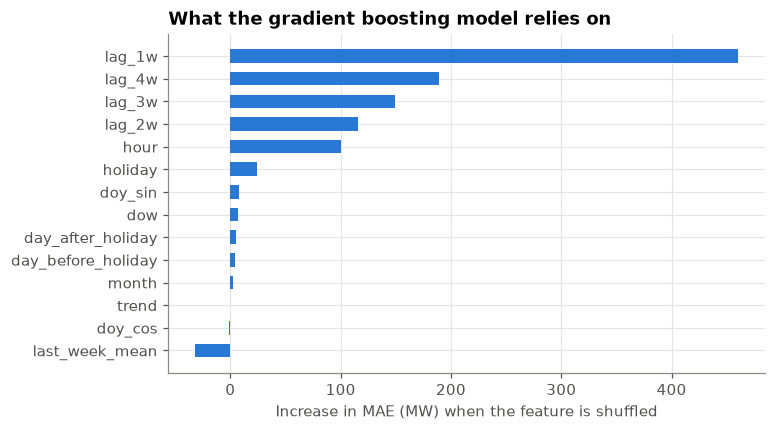

In [5]:
from sklearn.inspection import permutation_importance

# The last model was trained on data up to its retraining date, so the 4 weeks after it are unseen data
last_fit = origins[(len(origins) - 1) // RETRAIN_EVERY * RETRAIN_EVERY]
unseen = X_all.loc[last_fit:origins[-1] + pd.Timedelta(hours=167)].index
imp = permutation_importance(hgb, X_all.loc[unseen, FEATS], y.loc[unseen], n_repeats=5, random_state=42,
                             scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("Increase in MAE (MW) when the feature is shuffled")
ax.set_title("What the gradient boosting model relies on")
fig.savefig("../figures/feature_importance.png")
plt.show()